In [3]:
!pip install faker


   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB 320.0 kB/s eta 0:00:07
    --------------------------------------- 0.0/2.1 MB 388.9 kB/s eta 0:00:06
   - -------------------------------------- 0.1/2.1 MB 737.3 kB/s eta 0:00:03
   -- ------------------------------------- 0.2/2.1 MB 913.1 kB/s eta 0:00:03
   ----- ---------------------------------- 0.3/2.1 MB 1.4 MB/s eta 0:00:02
   ---------- ----------------------------- 0.5/2.1 MB 2.1 MB/s eta 0:00:01
   ----------- ---------------------------- 0.6/2.1 MB 2.1 MB/s eta 0:00:01
   ------------------- -------------------- 1.0/2.1 MB 2.8 MB/s eta 0:00:01
   ------------------------- -------------- 1.3/2.1 MB 3.4 MB/s eta 0:00:01
   --------------------------- ------------ 1.4/2.1 MB 3.4 MB/s eta 0:00:01
   ------------------------------- -------- 1.6/2.1 MB 3.4 MB/s eta 0:00:01
   ---------------

In [4]:
from faker import Faker
import random
import pandas as pd

fake = Faker("en_IN")

random.seed(42)

print("Setup completed!")

Setup completed!


In [7]:
from faker import Faker
import random
import pandas as pd

# Initialize Faker
fake = Faker("en_IN")

# Make results reproducible
random.seed(42)

# Number of customers
num_customers = 5000

# Indian cities
cities = [
    "Bengaluru",
    "Mumbai",
    "Delhi",
    "Hyderabad",
    "Chennai",
    "Pune",
    "Kolkata",
    "Ahmedabad",
    "Jaipur",
    "Kochi"
]

# Gender options
genders = ["Male", "Female"]

# Create customer data
customers = []

for i in range(1, num_customers + 1):
    
    customer = {
        "Customer_ID": f"C{i:05d}",
        "Name": fake.name(),
        "Age": random.randint(18, 60),
        "Gender": random.choice(genders),
        "City": random.choice(cities)
    }
    
    customers.append(customer)

# Convert to DataFrame
customers_df = pd.DataFrame(customers)

# Display first 5 customers
customers_df.head()

,Customer_ID,Name,Age,Gender,City
0,C00001,Vidhi Shah,58,Male,Bengaluru
1,C00002,Saanvi Seshadri,35,Male,Hyderabad
2,C00003,Agastya Cherian,26,Male,Jaipur
3,C00004,Lakshit Kohli,23,Female,Bengaluru
4,C00005,Hemang Kalla,19,Male,Hyderabad


In [9]:
# Number of transactions
num_transactions = 25000

# Product categories
categories = [
    "Electronics",
    "Clothing",
    "Beauty",
    "Home & Kitchen",
    "Sports",
    "Books",
    "Groceries"
]

# Payment methods
payment_methods = [
    "UPI",
    "Credit Card",
    "Debit Card",
    "Cash",
    "Net Banking"
]

# Create transaction data
transactions = []

for i in range(1, num_transactions + 1):
    
    customer_id = random.choice(customers_df["Customer_ID"])
    
    transaction = {
        "Transaction_ID": f"T{i:05d}",
        "Customer_ID": customer_id,
        "Purchase_Date": fake.date_between(
            start_date="-2y",
            end_date="today"
        ),
        "Category": random.choice(categories),
        "Quantity": random.randint(1, 5),
        "Unit_Price": random.randint(200, 50000),
        "Payment_Method": random.choice(payment_methods)
    }
    
    transactions.append(transaction)

# Convert to DataFrame
transactions_df = pd.DataFrame(transactions)

# Display first 5 rows
transactions_df.head()

,Transaction_ID,Customer_ID,Purchase_Date,Category,Quantity,Unit_Price,Payment_Method
0,T00001,C02658,2025-07-28,Groceries,4,30584,Cash
1,T00002,C03705,2026-03-07,Clothing,2,48556,Cash
2,T00003,C03438,2026-07-24,Electronics,2,20956,Cash
3,T00004,C01224,2025-05-31,Home & Kitchen,3,1114,Cash
4,T00005,C01416,2025-01-03,Clothing,5,12252,Credit Card


In [13]:
# Create the Analysis Date
transactions_df["Purchase_Date"].max()

analysis_date = transactions_df["Purchase_Date"].max() + pd.Timedelta(days=1)

print(analysis_date)

2026-10-02


In [31]:
# Calculate RFM
transactions_df['Revenue'] = transactions_df['Quantity'] * transactions_df['Unit_Price']
rfm = transactions_df.groupby("Customer_ID").agg({
    "Purchase_Date": lambda x: (analysis_date - x.max()).days,
    "Transaction_ID": "count",
    "Revenue": "sum"
})

# Rename the columns
rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]
rfm.head()


,Recency,Frequency,Monetary
Customer_ID,,,
C00001,111,5,442199
C00002,110,5,370714
C00003,279,1,138224
C00004,139,5,393730
C00005,122,9,366585


In [35]:
# Basic RFM Analysis
rfm["Recency"].mean(),
rfm["Frequency"].mean(),
rfm["Monetary"].mean()

380563.6995569875

In [43]:
#highest-spending customers
rfm.sort_values(
    "Monetary",
    ascending=False
).head(10)

#most frequent customers
rfm.sort_values(
    "Frequency",
    ascending=False
).head(10)

#most recent customers
rfm.sort_values(
    "Recency",
    ascending=True
).head(10)

,Recency,Frequency,Monetary
Customer_ID,,,
C04575,1,7,602286
C03403,1,12,945711
C01328,1,4,454894
C03340,1,10,979051
C01218,1,6,504054
C03342,1,1,169012
C01006,1,4,554980
C00495,1,7,547330
C01891,1,6,590700


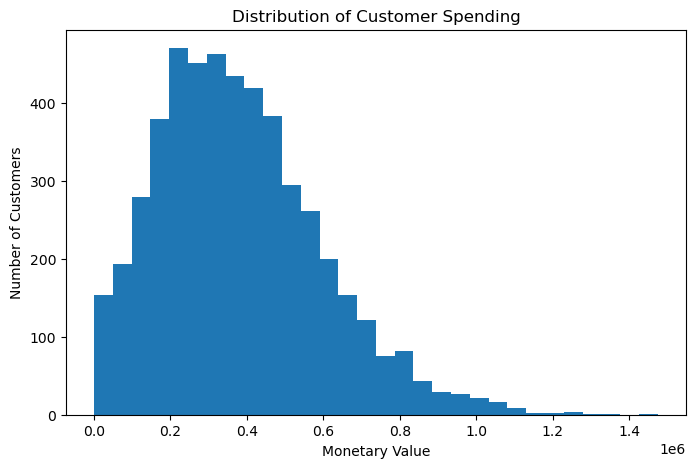

In [45]:
# Visualize RFM
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(rfm["Monetary"], bins=30)

plt.title("Distribution of Customer Spending")
plt.xlabel("Monetary Value")
plt.ylabel("Number of Customers")

plt.show()

In [47]:
rfm.head()

,Recency,Frequency,Monetary
Customer_ID,,,
C00001,111,5,442199
C00002,110,5,370714
C00003,279,1,138224
C00004,139,5,393730
C00005,122,9,366585


In [49]:
rfm.shape

(4966, 3)

In [53]:
customers_df.to_csv("customers.csv", index=False)

In [55]:
transactions_df.to_csv("transactions.csv", index=False)

In [57]:
import os

print(os.listdir())

['.ai-navigator', '.anaconda', '.android', '.conda', '.condarc', '.continuum', '.copilot', '.eclipse', '.emulator_console_auth_token', '.gitconfig', '.gradle', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jmc', '.jupyter', '.mamba', '.matplotlib', '.spss', '.spyder-py3', '.virtual_documents', '.vscode', '.vscode-shared', 'anaconda3', 'AndroidStudioProjects', 'ansel', 'AppData', 'Application Data', 'booking_data (1).xlsx', 'booking_data.xlsx', 'booking_data_cleaned.xlsx', 'class on python in spyder.py', 'classwork.ipynb', 'clustered_output.csv', 'Contacts', 'Cookies', 'customers.csv', 'customer_feedback.txt', 'customer_info.csv', 'customer_support_tickets_dataset.csv', 'Documents', 'Downloads', 'employee_salary_data.csv', 'evisort_contracts_dataset.csv', 'Favorites', 'house_prices.csv', 'HUL_BalanceSheet.xlsx', 'HUL_CashFlow.xlsx', 'java_error_in_studio_29184.log', 'Jedi', 'Links', 'Local Settings', 'mobile_personalization_powerbi.csv', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT'

In [59]:
with pd.ExcelWriter("customer_segmentation_dataset.xlsx") as writer:
    customers_df.to_excel(
        writer,
        sheet_name="Customers",
        index=False
    )
    
    transactions_df.to_excel(
        writer,
        sheet_name="Transactions",
        index=False
    )

In [ ]:
# cleaning data

In [61]:
customers_df.head()
customers_df.shape

(5000, 5)

In [63]:
transactions_df.head()
transactions_df.shape

(25000, 8)

In [65]:
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Customer_ID  5000 non-null   object
 1   Name         5000 non-null   object
 2   Age          5000 non-null   int64 
 3   Gender       5000 non-null   object
 4   City         5000 non-null   object
dtypes: int64(1), object(4)
memory usage: 195.4+ KB


In [67]:
transactions_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Transaction_ID  25000 non-null  object
 1   Customer_ID     25000 non-null  object
 2   Purchase_Date   25000 non-null  object
 3   Category        25000 non-null  object
 4   Quantity        25000 non-null  int64 
 5   Unit_Price      25000 non-null  int64 
 6   Payment_Method  25000 non-null  object
 7   Revenue         25000 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 1.5+ MB


In [69]:
customers_df.isnull().sum()

Customer_ID    0
Name           0
Age            0
Gender         0
City           0
dtype: int64

In [71]:
transactions_df.isnull().sum()

Transaction_ID    0
Customer_ID       0
Purchase_Date     0
Category          0
Quantity          0
Unit_Price        0
Payment_Method    0
Revenue           0
dtype: int64

In [73]:
customers_df.duplicated().sum()

0

In [75]:
transactions_df.duplicated().sum()

0

In [77]:
customers_df["Age"].min()

18

In [79]:
customers_df["Age"].max()

60

In [81]:
customers_df["Age"].describe()

count    5000.000000
mean       39.187200
std        12.315896
min        18.000000
25%        29.000000
50%        39.000000
75%        50.000000
max        60.000000
Name: Age, dtype: float64

In [83]:
transactions_df["Quantity"].describe()

count    25000.000000
mean         3.007960
std          1.417821
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: Quantity, dtype: float64

In [85]:
transactions_df["Unit_Price"].describe()

count    25000.000000
mean     25077.148800
std      14361.699639
min        203.000000
25%      12514.750000
50%      25208.000000
75%      37502.750000
max      49999.000000
Name: Unit_Price, dtype: float64

In [87]:
transactions_df["Revenue"].describe()

count     25000.000000
mean      75595.173280
std       59806.796297
min         203.000000
25%       27880.000000
50%       58644.500000
75%      113481.750000
max      249985.000000
Name: Revenue, dtype: float64

In [89]:
transactions_df["Category"].value_counts()

Category
Clothing          3618
Beauty            3606
Home & Kitchen    3583
Groceries         3580
Electronics       3573
Books             3521
Sports            3519
Name: count, dtype: int64

In [91]:
transactions_df["Payment_Method"].value_counts()

Payment_Method
Net Banking    5074
UPI            5048
Credit Card    5009
Debit Card     4936
Cash           4933
Name: count, dtype: int64

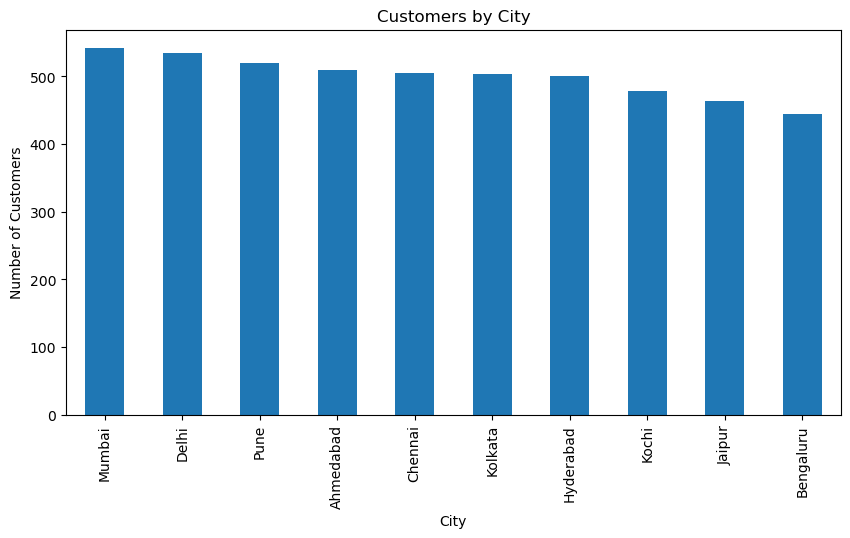

In [93]:
#Our first visualization
import matplotlib.pyplot as plt

customers_df["City"].value_counts().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Customers by City")
plt.xlabel("City")
plt.ylabel("Number of Customers")

plt.show()

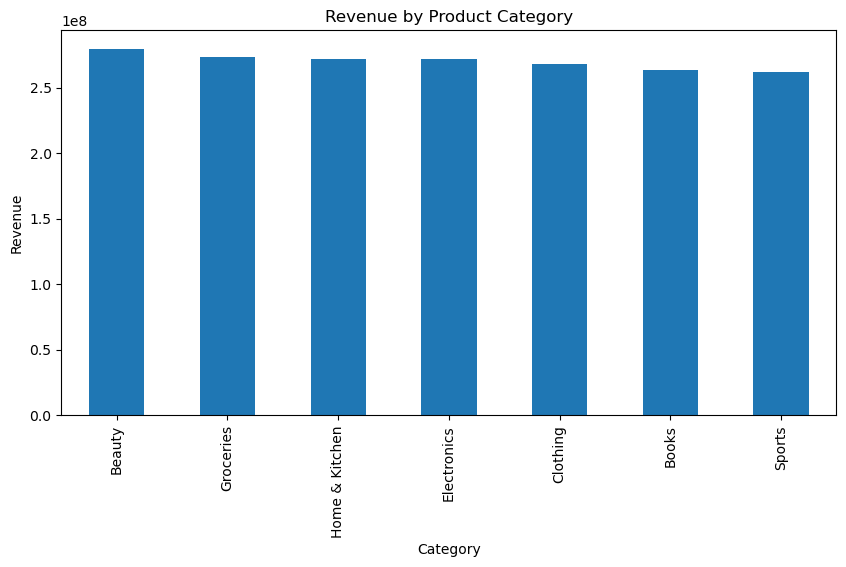

In [95]:
category_revenue = transactions_df.groupby(
    "Category"
)["Revenue"].sum().sort_values(ascending=False)

category_revenue.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")

plt.show()

In [99]:
# rfm cleaner

In [101]:
# RFM Analysis
# Create the analysis date
analysis_date = transactions_df["Purchase_Date"].max() + pd.Timedelta(days=1)

print("Analysis Date:", analysis_date)

Analysis Date: 2026-10-02


In [105]:
#Create the RFM table
rfm = transactions_df.groupby("Customer_ID").agg(
    Last_Purchase=("Purchase_Date", "max"),
    Frequency=("Transaction_ID", "count"),
    Monetary=("Revenue", "sum")
).reset_index()

In [111]:
#Calculate Recency
rfm["Recency"] = (
    pd.to_datetime(analysis_date) - pd.to_datetime(rfm["Last_Purchase"])
).dt.days

In [113]:
# Keep only the RFM columns
rfm = rfm[
    ["Customer_ID", "Recency", "Frequency", "Monetary"]
]
rfm.head()

,Customer_ID,Recency,Frequency,Monetary
0,C00001,111,5,442199
1,C00002,110,5,370714
2,C00003,279,1,138224
3,C00004,139,5,393730
4,C00005,122,9,366585


In [115]:
# Check the size
rfm.shape
random.choice(customers_df["Customer_ID"])

'C04638'

In [117]:
rfm.describe()

,Recency,Frequency,Monetary
count,4966.000000,4966.000000,4.966000e+03
mean,140.640959,5.034233,3.805637e+05
std,132.241024,2.214671,2.131567e+05
min,1.000000,1.000000,5.140000e+02
25%,41.000000,3.000000,2.236018e+05
50%,100.000000,5.000000,3.549660e+05
75%,198.000000,6.000000,5.080995e+05
max,728.000000,14.000000,1.474576e+06


In [119]:
# Highest spending
rfm.sort_values(
    "Monetary",
    ascending=False
).head(10)

,Customer_ID,Recency,Frequency,Monetary
1783,C01795,246,13,1474576
3972,C04003,3,11,1339633
945,C00950,55,10,1281590
976,C00981,119,9,1260004
674,C00678,61,12,1254947
2333,C02350,89,14,1241167
3393,C03424,11,11,1209045
178,C00180,26,13,1201385
620,C00624,107,10,1166597
3902,C03933,17,12,1131570


In [121]:
# Most frequent customers
rfm.sort_values(
    "Frequency",
    ascending=False
).head(10)

,Customer_ID,Recency,Frequency,Monetary
3547,C03578,177,14,1054165
3923,C03954,17,14,878194
1219,C01227,48,14,864039
2333,C02350,89,14,1241167
1783,C01795,246,13,1474576
3407,C03438,18,13,693970
2588,C02608,65,13,850952
3660,C03691,35,13,812490
2366,C02384,62,13,793923
178,C00180,26,13,1201385


In [123]:
# Most recent customers
rfm.sort_values(
    "Recency",
    ascending=True
).head(10)

,Customer_ID,Recency,Frequency,Monetary
4542,C04575,1,7,602286
3372,C03403,1,12,945711
1320,C01328,1,4,454894
3309,C03340,1,10,979051
1211,C01218,1,6,504054
3311,C03342,1,1,169012
1001,C01006,1,4,554980
491,C00495,1,7,547330
1879,C01891,1,6,590700
895,C00899,1,10,747465


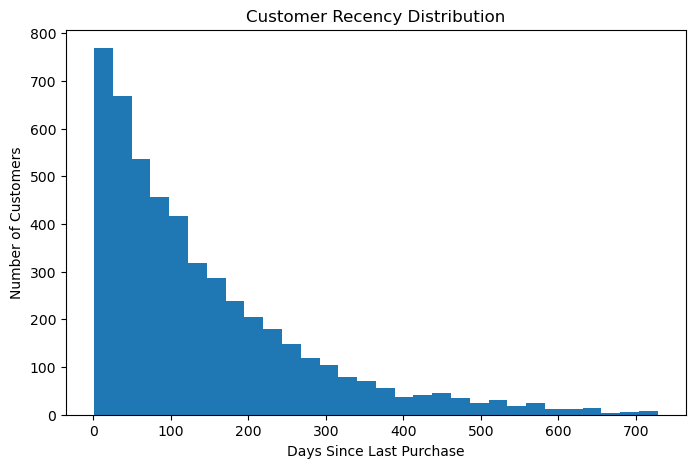

In [125]:
# Visualize RFM
plt.figure(figsize=(8, 5))

plt.hist(rfm["Recency"], bins=30)

plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.show()

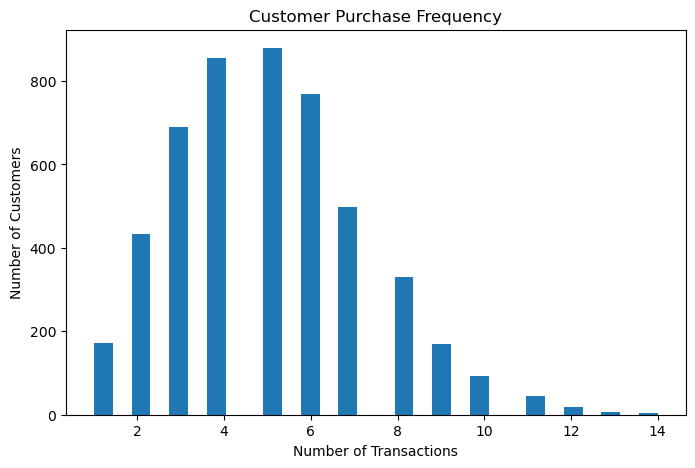

In [127]:
plt.figure(figsize=(8, 5))

plt.hist(rfm["Frequency"], bins=30)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")

plt.show()

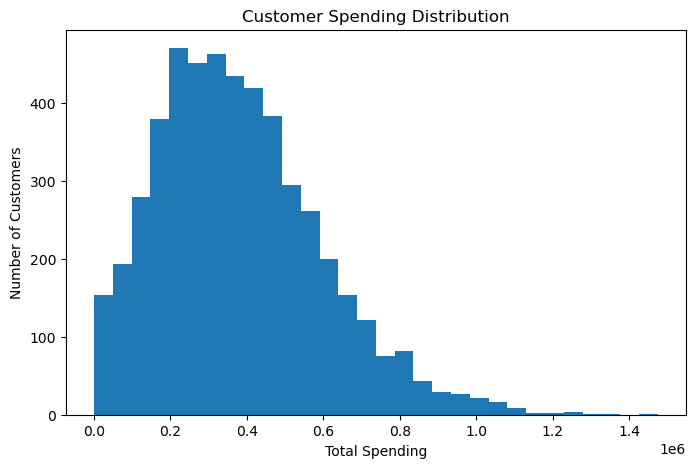

In [129]:
plt.figure(figsize=(8, 5))

plt.hist(rfm["Monetary"], bins=30)

plt.title("Customer Spending Distribution")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")

plt.show()

In [131]:
# Save your RFM dataset
rfm.to_csv(
    "rfm_customer_data.csv",
    index=False
)

In [133]:
# Prepare RFM Data for K-Means
# First, check for zero/negative values
rfm[["Recency", "Frequency", "Monetary"]].min()
rfm[["Recency", "Frequency", "Monetary"]].isnull().sum()
rfm[["Recency", "Frequency", "Monetary"]].skew()


Recency      1.519164
Frequency    0.505559
Monetary     0.727000
dtype: float64

In [139]:
import numpy as np

rfm_log = np.log1p(
    rfm[["Recency", "Frequency", "Monetary"]]
)
rfm_log.head()


,Recency,Frequency,Monetary
0,4.718499,1.791759,12.999518
1,4.709530,1.791759,12.823189
2,5.634790,0.693147,11.836638
3,4.941642,1.791759,12.883423
4,4.812184,2.302585,12.811988


In [141]:
#  Standardize the data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

In [143]:
# Convert it back to a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)
rfm_scaled.head()

,Recency,Frequency,Monetary
0,0.239130,0.169346,0.476612
1,0.231364,0.169346,0.241407
2,1.032490,-2.621991,-1.074555
3,0.432336,0.169346,0.321754
4,0.320246,1.467243,0.226467


In [145]:
# Now we choose the number of clusters
from sklearn.cluster import KMeans
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    
    inertia.append(kmeans.inertia_)

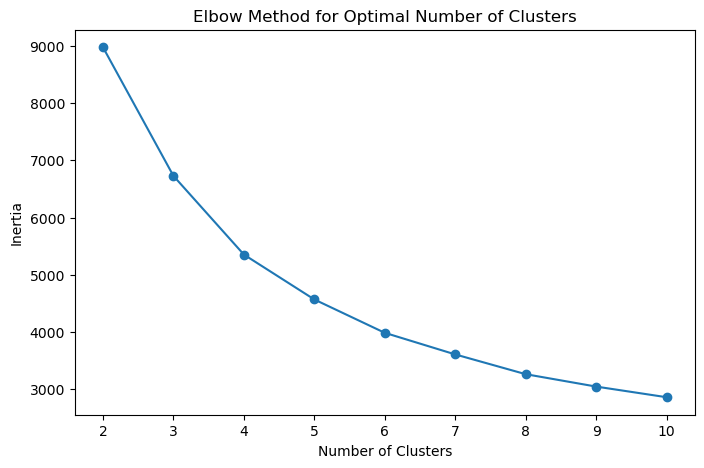

In [147]:
# Create the Elbow Graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.show()

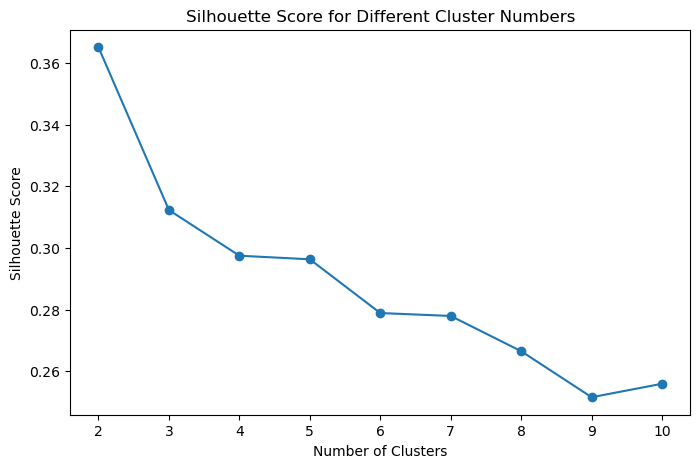

In [151]:
# Confirm the number of clusters
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(rfm_scaled)
    
    score = silhouette_score(rfm_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different Cluster Numbers")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.show()

In [153]:
# Run K-Means for 2, 3, 4 and 5
results = []

for k in [2, 3, 4, 5]:
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(rfm_scaled)
    
    temp = rfm.copy()
    temp["Cluster"] = labels
    
    profile = temp.groupby("Cluster").agg(
        Customers=("Customer_ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    ).reset_index()
    
    profile["K"] = k
    
    results.append(profile)

cluster_comparison = pd.concat(results, ignore_index=True)

cluster_comparison

,Cluster,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,K
0,0,1735,225.135447,2.895101,191220.390778,2
1,1,3231,95.268647,6.182916,482238.302074,2
2,0,1160,232.617241,2.442241,146155.538793,3
3,1,1372,25.247085,6.295190,485367.519679,3
4,2,2434,161.852095,5.558751,433202.411668,3
5,0,1670,116.886826,6.963473,557506.902395,4
6,1,1744,190.723624,3.845757,280767.409404,4
7,2,563,271.053286,1.900533,89005.539964,4
8,3,989,18.197169,5.656218,423735.413549,4
9,0,1284,232.271028,3.517913,258240.143302,5


In [155]:
# Create the FINAL K-Means Model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)
rfm.head()

,Customer_ID,Recency,Frequency,Monetary,Cluster
0,C00001,111,5,442199,0
1,C00002,110,5,370714,1
2,C00003,279,1,138224,2
3,C00004,139,5,393730,1
4,C00005,122,9,366585,0


In [157]:
# Create the final cluster profile
cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).reset_index()

cluster_profile

,Cluster,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
0,0,1670,116.886826,6.963473,557506.902395
1,1,1744,190.723624,3.845757,280767.409404
2,2,563,271.053286,1.900533,89005.539964
3,3,989,18.197169,5.656218,423735.413549


In [159]:
# Give the clusters business names
cluster_names = {
    0: "High-Value Frequent",
    1: "Regular Customers",
    2: "Low-Value Inactive",
    3: "Recent High-Value"
}

rfm["Customer_Segment"] = rfm["Cluster"].map(cluster_names)
rfm.head()

,Customer_ID,Recency,Frequency,Monetary,Cluster,Customer_Segment
0,C00001,111,5,442199,0,High-Value Frequent
1,C00002,110,5,370714,1,Regular Customers
2,C00003,279,1,138224,2,Low-Value Inactive
3,C00004,139,5,393730,1,Regular Customers
4,C00005,122,9,366585,0,High-Value Frequent


In [161]:
# See the final segments
rfm["Customer_Segment"].value_counts()

Customer_Segment
Regular Customers      1744
High-Value Frequent    1670
Recent High-Value       989
Low-Value Inactive      563
Name: count, dtype: int64

In [165]:
# Analyze the Customer Segments
segment_summary = rfm.groupby("Customer_Segment").agg(
    Customers=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).reset_index()

segment_summary

#Calculate Customer Percentage
segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum()
) * 100
segment_summary

,Customer_Segment,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage
0,High-Value Frequent,1670,116.886826,6.963473,557506.902395,931036527,33.628675
1,Low-Value Inactive,563,271.053286,1.900533,89005.539964,50110119,11.337092
2,Recent High-Value,989,18.197169,5.656218,423735.413549,419074324,19.915425
3,Regular Customers,1744,190.723624,3.845757,280767.409404,489658362,35.118808


In [167]:
# Calculate Revenue Percentage
segment_summary["Revenue_Percentage"] = (
    segment_summary["Total_Revenue"]
    / segment_summary["Total_Revenue"].sum()
) * 100
# Format the numbers
segment_summary["Customer_Percentage"] = (
    segment_summary["Customer_Percentage"].round(2)
)

segment_summary["Revenue_Percentage"] = (
    segment_summary["Revenue_Percentage"].round(2)
)

segment_summary["Avg_Recency"] = (
    segment_summary["Avg_Recency"].round(2)
)

segment_summary["Avg_Frequency"] = (
    segment_summary["Avg_Frequency"].round(2)
)

segment_summary["Avg_Monetary"] = (
    segment_summary["Avg_Monetary"].round(2)
)

segment_summary["Total_Revenue"] = (
    segment_summary["Total_Revenue"].round(2)
)

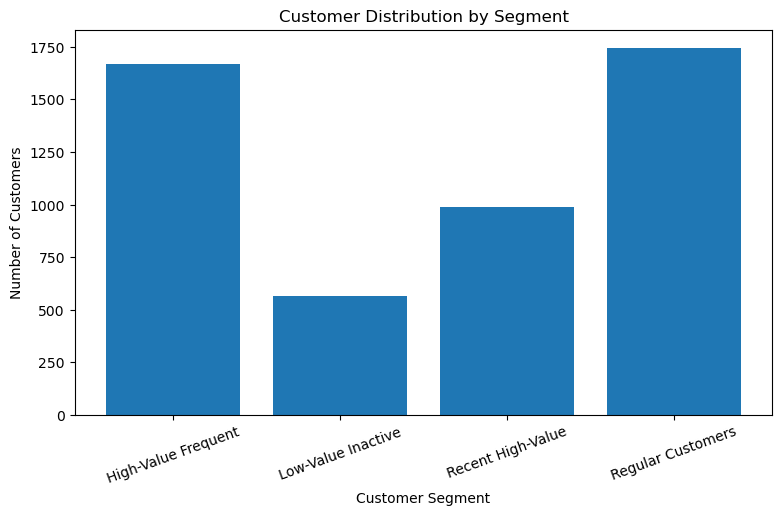

In [169]:
# Customer Distribution Chart
plt.figure(figsize=(9, 5))

plt.bar(
    segment_summary["Customer_Segment"],
    segment_summary["Customers"]
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

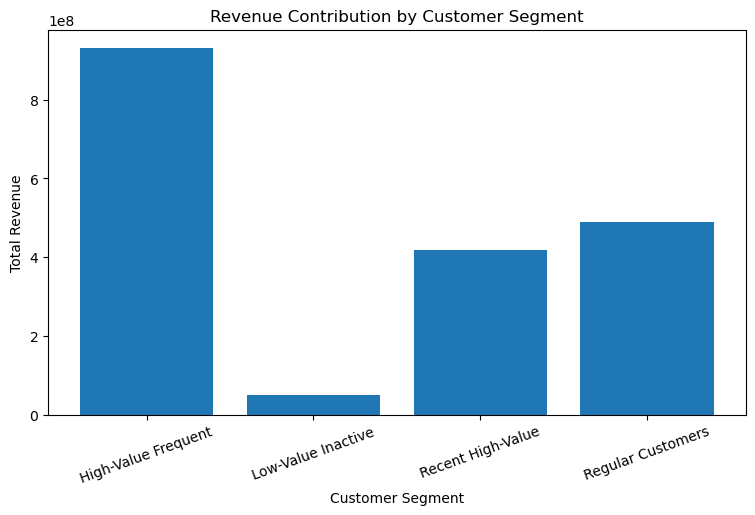

In [171]:
# Revenue by Segment
plt.figure(figsize=(9, 5))

plt.bar(
    segment_summary["Customer_Segment"],
    segment_summary["Total_Revenue"]
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")

plt.xticks(rotation=20)

plt.show()

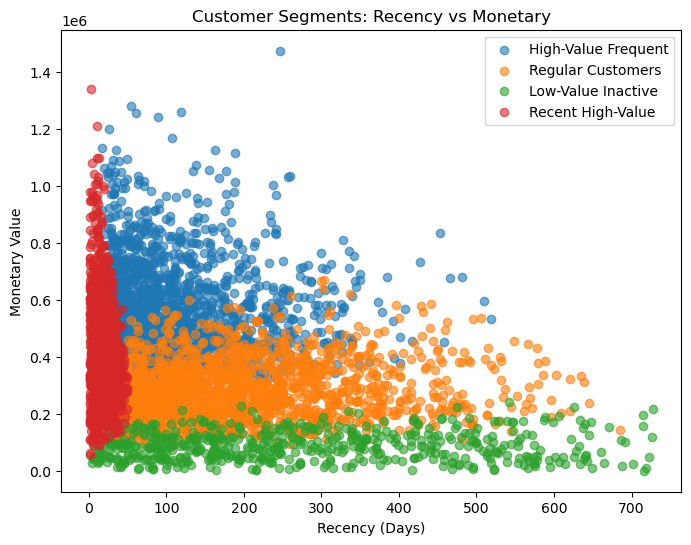

In [173]:
# Recency vs Monetary
plt.figure(figsize=(8, 6))

for segment in rfm["Customer_Segment"].unique():
    
    data = rfm[
        rfm["Customer_Segment"] == segment
    ]
    
    plt.scatter(
        data["Recency"],
        data["Monetary"],
        label=segment,
        alpha=0.6
    )

plt.title("Customer Segments: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value")

plt.legend()

plt.show()

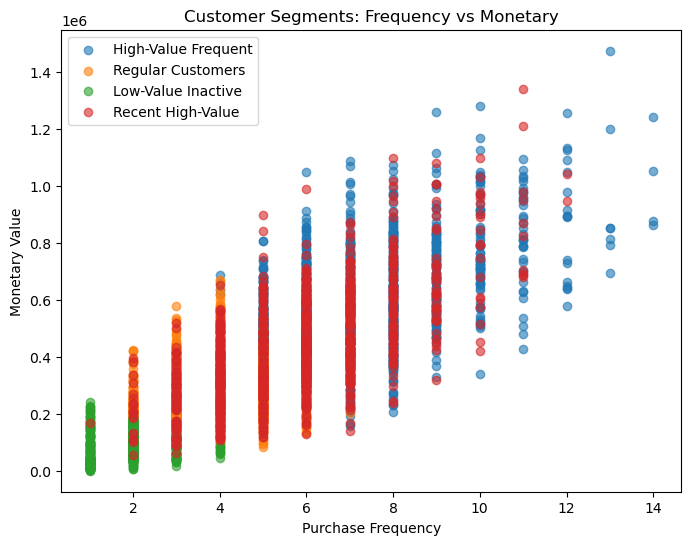

In [175]:
# Frequency vs Monetary
plt.figure(figsize=(8, 6))

for segment in rfm["Customer_Segment"].unique():
    
    data = rfm[
        rfm["Customer_Segment"] == segment
    ]
    
    plt.scatter(
        data["Frequency"],
        data["Monetary"],
        label=segment,
        alpha=0.6
    )

plt.title("Customer Segments: Frequency vs Monetary")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary Value")

plt.legend()

plt.show()

In [177]:
# Analyze Category Preferences by Segment
segment_transactions = transactions_df.merge(
    rfm[["Customer_ID", "Customer_Segment"]],
    on="Customer_ID",
    how="inner"
)
segment_transactions.head()

,Transaction_ID,Customer_ID,Purchase_Date,Category,Quantity,Unit_Price,Payment_Method,Revenue,Customer_Segment
0,T00001,C02658,2025-07-28,Groceries,4,30584,Cash,122336,Regular Customers
1,T00002,C03705,2026-03-07,Clothing,2,48556,Cash,97112,High-Value Frequent
2,T00003,C03438,2026-07-24,Electronics,2,20956,Cash,41912,High-Value Frequent
3,T00004,C01224,2025-05-31,Home & Kitchen,3,1114,Cash,3342,Recent High-Value
4,T00005,C01416,2025-01-03,Clothing,5,12252,Credit Card,61260,High-Value Frequent


In [179]:
category_segment = segment_transactions.groupby(
    ["Customer_Segment", "Category"]
)["Revenue"].sum().reset_index()

category_segment
top_categories = (
    category_segment
    .sort_values(
        ["Customer_Segment", "Revenue"],
        ascending=[True, False]
    )
    .groupby("Customer_Segment")
    .head(1)
)

top_categories
segment_category_pivot = pd.pivot_table(
    segment_transactions,
    values="Revenue",
    index="Customer_Segment",
    columns="Category",
    aggfunc="sum",
    fill_value=0
)

segment_category_pivot

Category,Beauty,Books,Clothing,Electronics,Groceries,Home & Kitchen,Sports
Customer_Segment,,,,,,,
High-Value Frequent,138383732,124609639,134615104,135333257,133809085,136943333,127342377
Low-Value Inactive,7057173,7425690,6791126,8345464,7003932,6491730,6995004
Recent High-Value,64166654,60332331,57052924,59999119,61423330,57120273,58979693
Regular Customers,70252771,70923669,69318414,67975060,70938203,71473509,68776736


In [181]:
rfm.to_csv(
    "customer_segments.csv",
    index=False
)

In [183]:
segment_transactions.to_csv(
    "transactions_with_segments.csv",
    index=False
)

In [185]:
segment_summary

,Customer_Segment,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage,Revenue_Percentage
0,High-Value Frequent,1670,116.89,6.96,557506.90,931036527,33.63,49.26
1,Low-Value Inactive,563,271.05,1.90,89005.54,50110119,11.34,2.65
2,Recent High-Value,989,18.20,5.66,423735.41,419074324,19.92,22.17
3,Regular Customers,1744,190.72,3.85,280767.41,489658362,35.12,25.91


In [187]:
top_categories

,Customer_Segment,Category,Revenue
0,High-Value Frequent,Beauty,138383732
10,Low-Value Inactive,Electronics,8345464
14,Recent High-Value,Beauty,64166654
26,Regular Customers,Home & Kitchen,71473509
